In [8]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import MinMaxScaler

import os

# Print the current working directory
print("Current Working Directory:", os.getcwd())

# Load the datasets
mat_data = pd.read_csv('./student/student-mat.csv', sep=';')
por_data = pd.read_csv('./student/student-por.csv', sep=';')

combined_data = pd.concat([mat_data, por_data], ignore_index=True)

from sklearn.preprocessing import LabelEncoder

# encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    combined_data[feature] = label_encoder.fit_transform(combined_data[feature])


# one-hot endocing the categorical features
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']

combined_data = pd.get_dummies(combined_data, columns=categorical_features, drop_first=True)

# normalizing numeric features using min-max scaling
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

scaler = MinMaxScaler()
combined_data[numeric_features] = scaler.fit_transform(combined_data[numeric_features])

# Create a binary target variable
combined_data['G3_binary'] = (combined_data['G3'] > 0.5).astype(int)

# Define features and target
X = combined_data.drop(columns=['G3', 'G3_binary'])
y = combined_data['G3_binary']

Current Working Directory: c:\Users\ivoga\Documents\Git local repositories\projekt-R\testiranje


c:\Users\ivoga\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1237: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, binary problems will be fit as proper binary  logistic regression models (as if multi_class='ovr' were set). Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\ivoga\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\ivoga\AppData\Local\Programs\Python\Python311\Lib\site

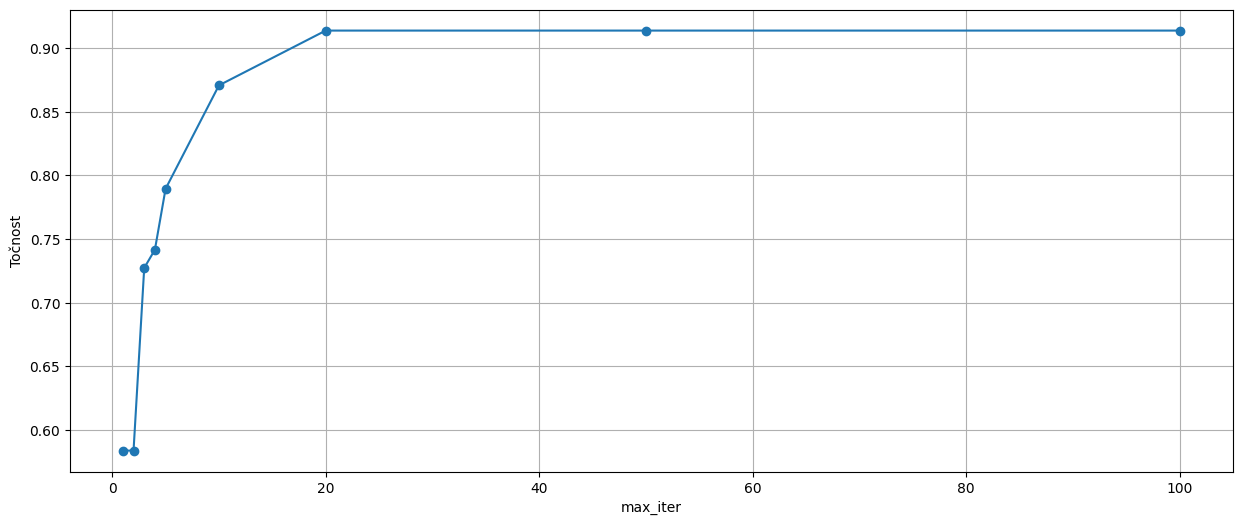

In [26]:
# Primjer podataka
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# Parametri za analizu
max_iter_values = [1, 2, 3, 4, 5, 10, 20, 50, 100,]

# Čuvanje rezultata
results = []

for max_iter in max_iter_values:
    model = LogisticRegression(max_iter=max_iter, multi_class='multinomial', random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results.append({'max_iter': max_iter, 'accuracy': accuracy})

# Pretvori rezultate u DataFrame
results_df = pd.DataFrame(results)

# Vizualizacija
plt.figure(figsize=(15, 6))
plt.plot(results_df['max_iter'], results_df['accuracy'], marker='o')
plt.xlabel('max_iter')
plt.ylabel('Točnost')
plt.grid(True)
plt.show()